In [1]:
# Import pandas library
import pandas as pd

# Print a success message
print("UPI Pulse - Data Analysis Started!")

UPI Pulse - Data Analysis Started!


In [2]:
# Import Path to work with file locations
from pathlib import Path

# Locate our project folder
project_folder = Path.cwd().resolve()

if project_folder.name == "notebooks":
    project_folder = project_folder.parent

# Find the Excel file inside data/raw
excel_files = list((project_folder / "data" / "raw").glob("*.xlsx"))

# Read the first Excel file
df = pd.read_excel(excel_files[0])

# Display the first 5 rows
df.head()

,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,March-2026,705,"22,641.11","29,52,542.05"
1,February-2026,694,"20,394.18","26,84,229.29"
2,January-2026,691,"21,703.44","28,33,481.22"
3,December-2025,685,"21,634.67","27,96,712.73"
4,November-2025,684,"20,466.98","26,31,632.63"


In [3]:
# Check the number of rows and columns
df.shape

(12, 4)

In [4]:
# Check column names and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Month                     12 non-null     str  
 1   No. of Banks live on UPI  12 non-null     int64
 2   Volume (In Mn.)           12 non-null     str  
 3   Value (In Cr.)            12 non-null     str  
dtypes: int64(1), str(3)
memory usage: 516.0 bytes


In [5]:
# Check missing values in each column
df.isnull().sum()

Month                       0
No. of Banks live on UPI    0
Volume (In Mn.)             0
Value (In Cr.)              0
dtype: int64

In [6]:
# Create a copy of the original dataset
df_clean = df.copy()

# Check the copied dataset
df_clean.head()

,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,March-2026,705,"22,641.11","29,52,542.05"
1,February-2026,694,"20,394.18","26,84,229.29"
2,January-2026,691,"21,703.44","28,33,481.22"
3,December-2025,685,"21,634.67","27,96,712.73"
4,November-2025,684,"20,466.98","26,31,632.63"


In [7]:
# Remove commas and convert Volume into numeric data
df_clean["Volume (In Mn.)"] = (
    df_clean["Volume (In Mn.)"]
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Remove commas and convert Value into numeric data
df_clean["Value (In Cr.)"] = (
    df_clean["Value (In Cr.)"]
    .str.replace(",", "", regex=False)
    .astype(float)
)

In [8]:
# Check the updated data types
df_clean.dtypes

Month                           str
No. of Banks live on UPI      int64
Volume (In Mn.)             float64
Value (In Cr.)              float64
dtype: object

In [9]:
# Convert Month column from text into datetime format

df_clean["Month"] = pd.to_datetime(
    df_clean["Month"],
    format="%B-%Y"
)

# Display the updated dates
df_clean["Month"]

0    2026-03-01
1    2026-02-01
2    2026-01-01
3    2025-12-01
4    2025-11-01
5    2025-10-01
6    2025-09-01
7    2025-08-01
8    2025-07-01
9    2025-06-01
10   2025-05-01
11   2025-04-01
Name: Month, dtype: datetime64[us]

In [10]:
# Check all column data types
df_clean.dtypes

Month                       datetime64[us]
No. of Banks live on UPI             int64
Volume (In Mn.)                    float64
Value (In Cr.)                     float64
dtype: object

In [11]:
# Check for duplicate rows
df_clean.duplicated().sum()

np.int64(0)

In [12]:
# Sort data from oldest month to newest month
df_clean = df_clean.sort_values("Month").reset_index(drop=True)

# Display the sorted dataset
df_clean

,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,2025-04-01,668,17893.42,2394925.87
1,2025-05-01,673,18677.46,2514297.01
2,2025-06-01,675,18395.01,2403930.69
3,2025-07-01,684,19467.95,2508498.09
4,2025-08-01,688,20008.31,2485472.91
5,2025-09-01,686,19633.43,2489736.54
6,2025-10-01,683,20700.92,2727790.68
7,2025-11-01,684,20466.98,2631632.63
8,2025-12-01,685,21634.67,2796712.73
9,2026-01-01,691,21703.44,2833481.22


In [13]:
# Final dataset dimensions
print("Rows and columns:", df_clean.shape)

# Check missing values
print("\nMissing values:")
print(df_clean.isnull().sum())

Rows and columns: (12, 4)

Missing values:
Month                       0
No. of Banks live on UPI    0
Volume (In Mn.)             0
Value (In Cr.)              0
dtype: int64


In [14]:
# Save cleaned dataset as a CSV file

output_path = project_folder / "data" / "processed" / "upi_cleaned.csv"

df_clean.to_csv(output_path, index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [1]:
# Generate descriptive statistics

df_clean.describe()

NameError: name 'df_clean' is not defined

In [3]:
# Import required libraries
import pandas as pd
from pathlib import Path

# Locate project folder
project_folder = Path.cwd()

if project_folder.name == "notebooks":
    project_folder = project_folder.parent

# Load cleaned dataset
df_clean = pd.read_csv(
    project_folder / "data" / "processed" / "upi_cleaned.csv",
    parse_dates=["Month"]
)

# Display descriptive statistics
df_clean.describe()

,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
count,12,12.000000,12.00000,1.200000e+01
mean,2025-09-15 18:00:00,684.666667,20134.74000,2.618604e+06
min,2025-04-01 00:00:00,668.000000,17893.42000,2.394926e+06
25%,2025-06-23 12:00:00,681.000000,19270.32750,2.488671e+06
50%,2025-09-16 00:00:00,684.500000,20201.24500,2.572965e+06
75%,2025-12-08 18:00:00,688.750000,20934.35750,2.745021e+06
max,2026-03-01 00:00:00,705.000000,22641.11000,2.952542e+06
std,NaN,9.838083,1426.26335,1.807203e+05


In [4]:
# Find the month with the highest transaction volume

highest_month = df_clean.loc[
    df_clean["Volume (In Mn.)"].idxmax()
]

print("Highest transaction volume:")
print(highest_month)

Highest transaction volume:
Month                       2026-03-01 00:00:00
No. of Banks live on UPI                    705
Volume (In Mn.)                        22641.11
Value (In Cr.)                       2952542.05
Name: 11, dtype: object


In [5]:
# Find the month with the lowest transaction volume

lowest_month = df_clean.loc[
    df_clean["Volume (In Mn.)"].idxmin()
]

print("Lowest transaction volume:")
print(lowest_month)

Lowest transaction volume:
Month                       2025-04-01 00:00:00
No. of Banks live on UPI                    668
Volume (In Mn.)                        17893.42
Value (In Cr.)                       2394925.87
Name: 0, dtype: object


In [6]:
# Calculate monthly transaction volume growth

df_clean["Volume Growth (%)"] = (
    df_clean["Volume (In Mn.)"].pct_change() * 100
)

# Display monthly growth
df_clean[["Month", "Volume (In Mn.)", "Volume Growth (%)"]]

,Month,Volume (In Mn.),Volume Growth (%)
0,2025-04-01,17893.42,NaN
1,2025-05-01,18677.46,4.381722
2,2025-06-01,18395.01,-1.512251
3,2025-07-01,19467.95,5.832777
4,2025-08-01,20008.31,2.775639
5,2025-09-01,19633.43,-1.873622
6,2025-10-01,20700.92,5.437104
7,2025-11-01,20466.98,-1.130095
8,2025-12-01,21634.67,5.705238
9,2026-01-01,21703.44,0.317869


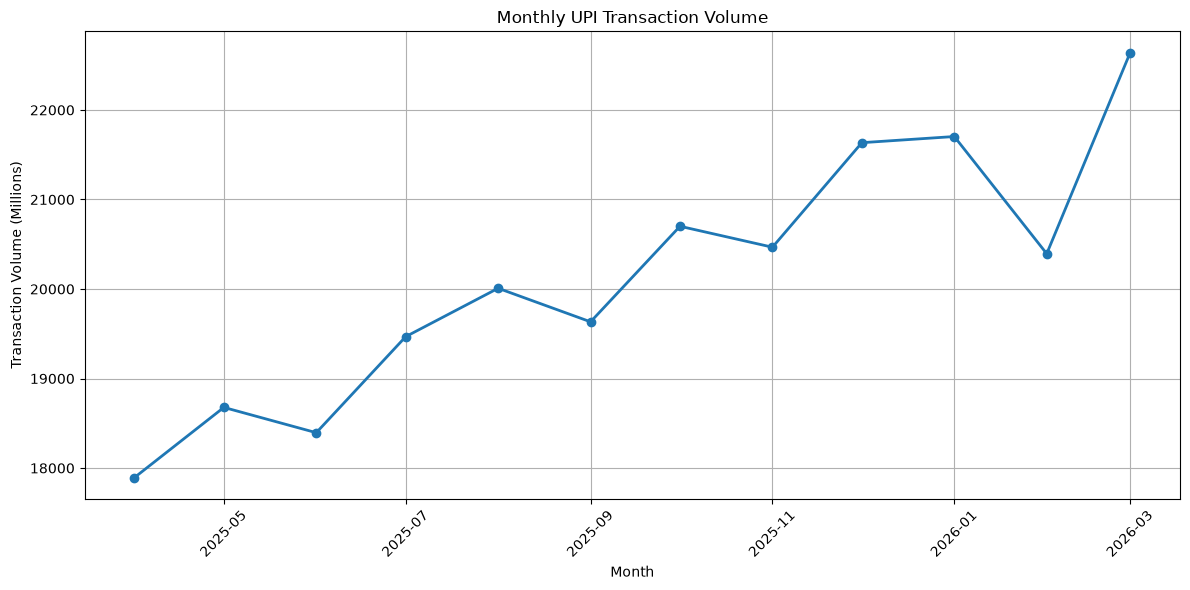

In [7]:
# Import visualization library
import matplotlib.pyplot as plt

# Create figure
plt.figure(figsize=(12, 6))

# Plot transaction volume
plt.plot(
    df_clean["Month"],
    df_clean["Volume (In Mn.)"],
    marker="o",
    linewidth=2
)

# Add chart title and labels
plt.title("Monthly UPI Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Transaction Volume (Millions)")

# Rotate month labels
plt.xticks(rotation=45)

# Add grid
plt.grid(True)

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()

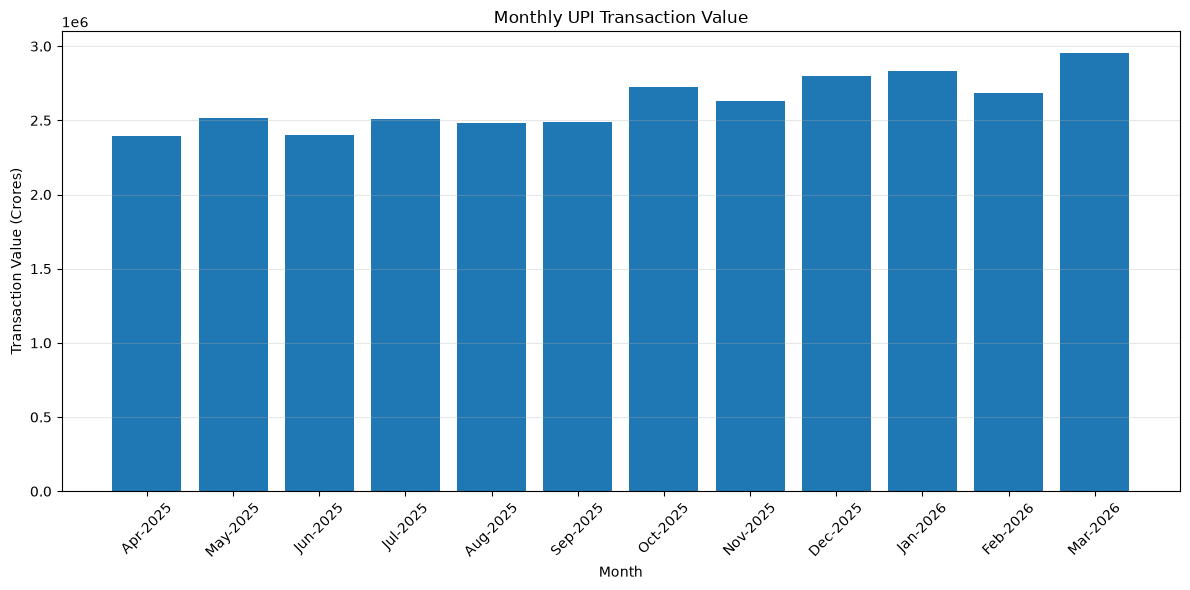

In [8]:
# Create a bar chart
plt.figure(figsize=(12, 6))

# Plot transaction values
plt.bar(
    df_clean["Month"].dt.strftime("%b-%Y"),
    df_clean["Value (In Cr.)"]
)

# Add title and labels
plt.title("Monthly UPI Transaction Value")
plt.xlabel("Month")
plt.ylabel("Transaction Value (Crores)")

# Rotate labels
plt.xticks(rotation=45)

# Add grid
plt.grid(axis="y", alpha=0.3)

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()

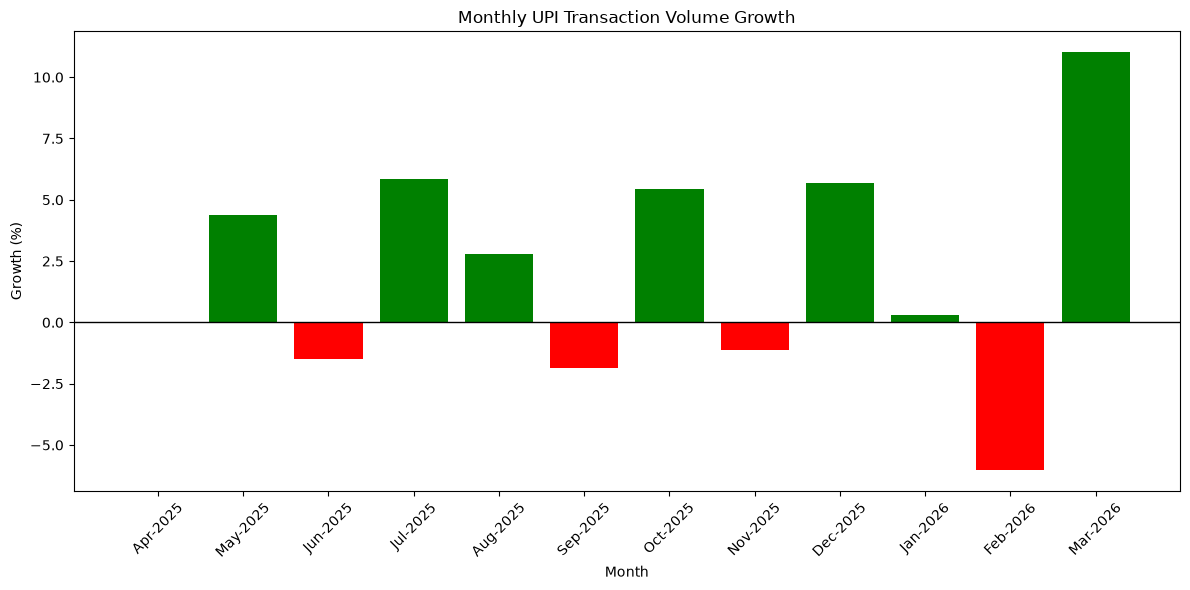

In [9]:
# Create monthly growth chart
plt.figure(figsize=(12, 6))

# Assign colors based on growth
colors = [
    "green" if growth >= 0 else "red"
    for growth in df_clean["Volume Growth (%)"]
]

# Plot monthly growth
plt.bar(
    df_clean["Month"].dt.strftime("%b-%Y"),
    df_clean["Volume Growth (%)"].fillna(0),
    color=colors
)

# Add title and labels
plt.title("Monthly UPI Transaction Volume Growth")
plt.xlabel("Month")
plt.ylabel("Growth (%)")

# Add horizontal zero line
plt.axhline(y=0, color="black", linewidth=1)

# Rotate month labels
plt.xticks(rotation=45)

# Adjust layout
plt.tight_layout()

# Display chart
plt.show()

In [10]:
# Create a folder for visualizations
charts_folder = project_folder / "reports" / "charts"

charts_folder.mkdir(parents=True, exist_ok=True)

print("Charts folder created successfully!")

Charts folder created successfully!


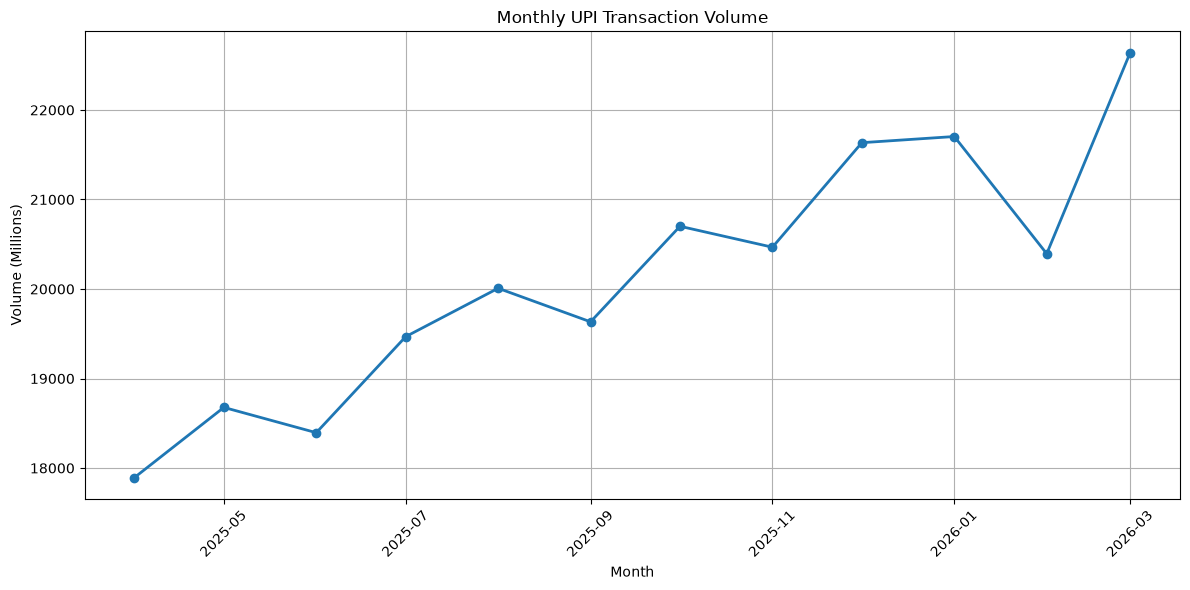

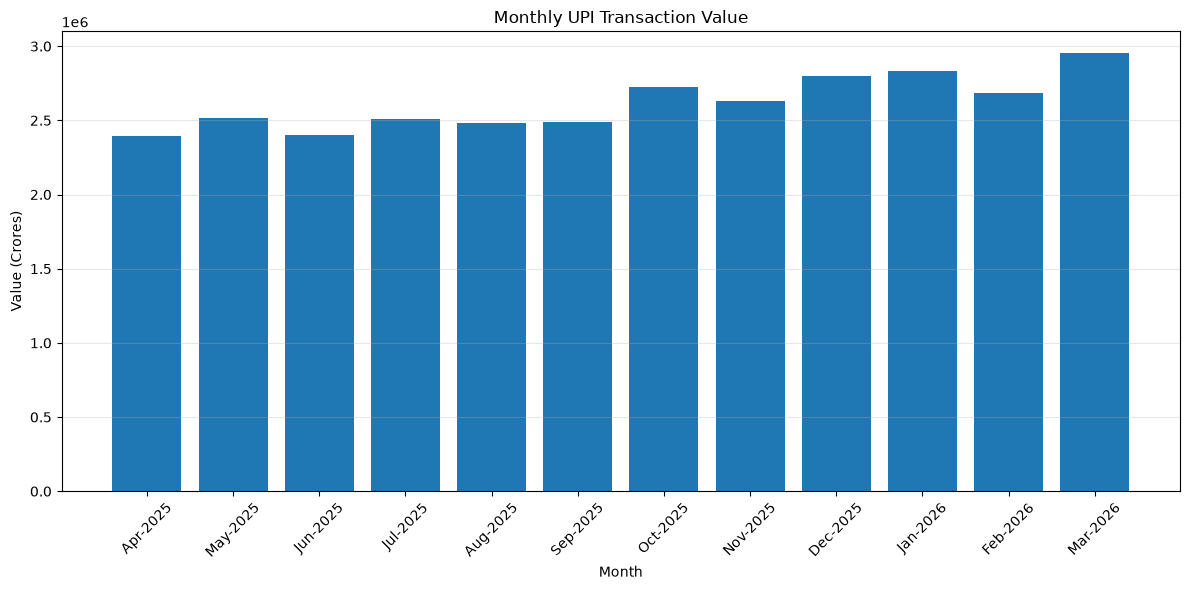

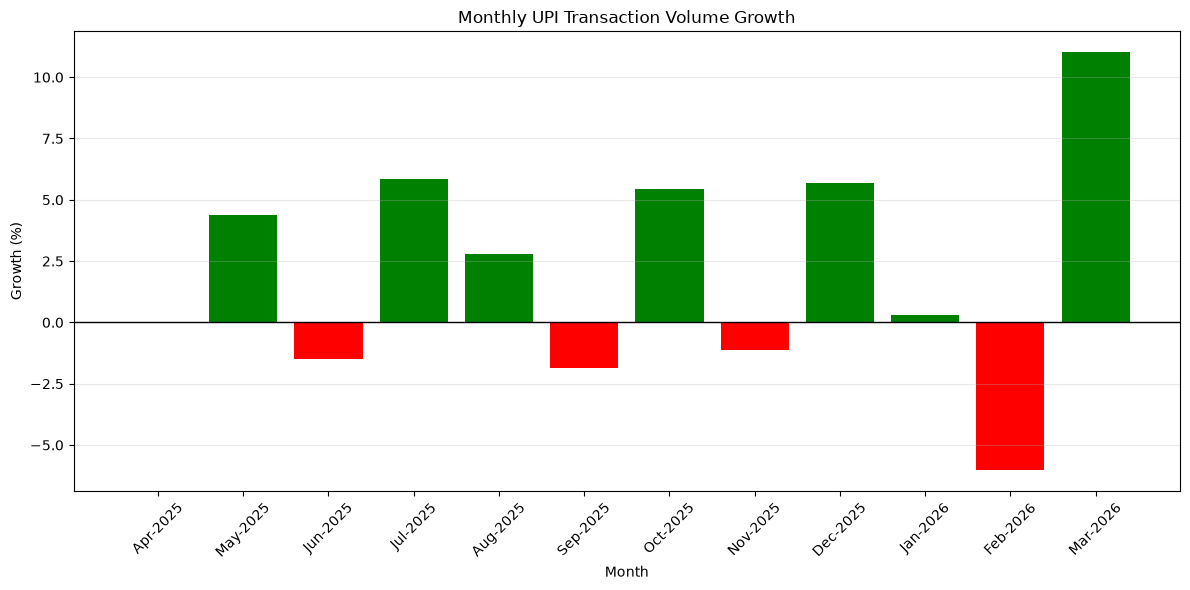

All 3 charts saved successfully!


In [11]:

# =====================================
# SAVE ALL UPI PULSE VISUALIZATIONS
# =====================================

# 1. Monthly Transaction Volume
plt.figure(figsize=(12, 6))

plt.plot(
    df_clean["Month"],
    df_clean["Volume (In Mn.)"],
    marker="o",
    linewidth=2
)

plt.title("Monthly UPI Transaction Volume")
plt.xlabel("Month")
plt.ylabel("Volume (Millions)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.savefig(
    charts_folder / "monthly_transaction_volume.png",
    dpi=300
)
plt.show()
plt.close()


# 2. Monthly Transaction Value
plt.figure(figsize=(12, 6))

plt.bar(
    df_clean["Month"].dt.strftime("%b-%Y"),
    df_clean["Value (In Cr.)"]
)

plt.title("Monthly UPI Transaction Value")
plt.xlabel("Month")
plt.ylabel("Value (Crores)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    charts_folder / "monthly_transaction_value.png",
    dpi=300
)
plt.show()
plt.close()


# 3. Monthly Transaction Growth
plt.figure(figsize=(12, 6))

colors = [
    "green" if growth >= 0 else "red"
    for growth in df_clean["Volume Growth (%)"]
]

plt.bar(
    df_clean["Month"].dt.strftime("%b-%Y"),
    df_clean["Volume Growth (%)"].fillna(0),
    color=colors
)

plt.title("Monthly UPI Transaction Volume Growth")
plt.xlabel("Month")
plt.ylabel("Growth (%)")
plt.axhline(y=0, color="black", linewidth=1)
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    charts_folder / "monthly_transaction_growth.png",
    dpi=300
)
plt.show()
plt.close()


print("All 3 charts saved successfully!")


In [12]:
# Check saved chart files

chart_files = list(charts_folder.glob("*.png"))

print("Saved visualization files:\n")

for file in chart_files:
    print(file.name)

print("\nTotal charts saved:", len(chart_files))

Saved visualization files:

monthly_transaction_growth.png
monthly_transaction_value.png
monthly_transaction_volume.png

Total charts saved: 3


In [13]:
# Calculate monthly transaction value growth

df_clean["Value Growth (%)"] = (
    df_clean["Value (In Cr.)"].pct_change() * 100
)

# Display monthly value growth

df_clean[[
    "Month",
    "Value (In Cr.)",
    "Value Growth (%)"
]]

,Month,Value (In Cr.),Value Growth (%)
0,2025-04-01,2394925.87,NaN
1,2025-05-01,2514297.01,4.984335
2,2025-06-01,2403930.69,-4.389550
3,2025-07-01,2508498.09,4.349851
4,2025-08-01,2485472.91,-0.917887
5,2025-09-01,2489736.54,0.171542
6,2025-10-01,2727790.68,9.561419
7,2025-11-01,2631632.63,-3.525126
8,2025-12-01,2796712.73,6.272916
9,2026-01-01,2833481.22,1.314704


In [14]:
# Find the month with highest value growth

highest_growth = df_clean.loc[
    df_clean["Value Growth (%)"].idxmax()
]

print("Highest transaction value growth:")
print(highest_growth)


# Find the month with lowest value growth

lowest_growth = df_clean.loc[
    df_clean["Value Growth (%)"].idxmin()
]

print("\nLowest transaction value growth:")
print(lowest_growth)

Highest transaction value growth:
Month                       2026-03-01 00:00:00
No. of Banks live on UPI                    705
Volume (In Mn.)                        22641.11
Value (In Cr.)                       2952542.05
Volume Growth (%)                     11.017506
Value Growth (%)                       9.995896
Name: 11, dtype: object

Lowest transaction value growth:
Month                       2026-02-01 00:00:00
No. of Banks live on UPI                    694
Volume (In Mn.)                        20394.18
Value (In Cr.)                       2684229.29
Volume Growth (%)                       -6.0325
Value Growth (%)                       -5.26744
Name: 10, dtype: object


In [15]:
# Compare transaction volume and value growth

growth_comparison = df_clean[[
    "Month",
    "Volume Growth (%)",
    "Value Growth (%)"
]]

# Display comparison
growth_comparison

,Month,Volume Growth (%),Value Growth (%)
0,2025-04-01,NaN,NaN
1,2025-05-01,4.381722,4.984335
2,2025-06-01,-1.512251,-4.389550
3,2025-07-01,5.832777,4.349851
4,2025-08-01,2.775639,-0.917887
5,2025-09-01,-1.873622,0.171542
6,2025-10-01,5.437104,9.561419
7,2025-11-01,-1.130095,-3.525126
8,2025-12-01,5.705238,6.272916
9,2026-01-01,0.317869,1.314704


In [16]:
# Calculate correlation between volume and value growth

correlation = df_clean[
    ["Volume Growth (%)", "Value Growth (%)"]
].corr()

# Display correlation
print("Correlation between volume and value growth:")
print(correlation)

Correlation between volume and value growth:
                   Volume Growth (%)  Value Growth (%)
Volume Growth (%)            1.00000           0.90254
Value Growth (%)             0.90254           1.00000


In [17]:
# Calculate average transaction value in rupees

df_clean["Average Transaction Value (₹)"] = (
    df_clean["Value (In Cr.)"] /
    df_clean["Volume (In Mn.)"] * 10
)

# Display the results

df_clean[[
    "Month",
    "Average Transaction Value (₹)"
]]

,Month,Average Transaction Value (₹)
0,2025-04-01,1338.439421
1,2025-05-01,1346.166454
2,2025-06-01,1306.838480
3,2025-07-01,1288.527087
4,2025-08-01,1242.220312
5,2025-09-01,1268.110840
6,2025-10-01,1317.714710
7,2025-11-01,1285.794304
8,2025-12-01,1292.699510
9,2026-01-01,1305.544752


In [18]:
# Find the month with highest average transaction value
highest_avg = df_clean.loc[
    df_clean["Average Transaction Value (₹)"].idxmax()
]

# Find the month with lowest average transaction value
lowest_avg = df_clean.loc[
    df_clean["Average Transaction Value (₹)"].idxmin()
]

# Display results
print("Highest Average Transaction Value:")
print("Month:", highest_avg["Month"])
print("Amount: ₹", round(highest_avg["Average Transaction Value (₹)"], 2))

print("\nLowest Average Transaction Value:")
print("Month:", lowest_avg["Month"])
print("Amount: ₹", round(lowest_avg["Average Transaction Value (₹)"], 2))

Highest Average Transaction Value:
Month: 2025-05-01 00:00:00
Amount: ₹ 1346.17

Lowest Average Transaction Value:
Month: 2025-08-01 00:00:00
Amount: ₹ 1242.22


In [19]:
# Generate business insights

total_transactions = df_clean["Volume (In Mn.)"].sum()

total_value = df_clean["Value (In Cr.)"].sum()

average_transactions = df_clean["Volume (In Mn.)"].mean()

average_value = df_clean["Value (In Cr.)"].mean()

highest_volume_month = df_clean.loc[
    df_clean["Volume (In Mn.)"].idxmax(), "Month"
]

lowest_volume_month = df_clean.loc[
    df_clean["Volume (In Mn.)"].idxmin(), "Month"
]

print("========== UPI PULSE BUSINESS INSIGHTS ==========")

print(f"Total monthly transaction volume: {total_transactions:,.2f} million")

print(f"Total monthly transaction value: ₹{total_value:,.2f} crore")

print(f"Average monthly transaction volume: {average_transactions:,.2f} million")

print(f"Average monthly transaction value: ₹{average_value:,.2f} crore")

print(f"Highest transaction month: {highest_volume_month.strftime('%B %Y')}")

print(f"Lowest transaction month: {lowest_volume_month.strftime('%B %Y')}")

========== UPI PULSE BUSINESS INSIGHTS ==========
Total monthly transaction volume: 241,616.88 million
Total monthly transaction value: ₹31,423,249.71 crore
Average monthly transaction volume: 20,134.74 million
Average monthly transaction value: ₹2,618,604.14 crore
Highest transaction month: March 2026
Lowest transaction month: April 2025


In [20]:
output_path = project_folder / "data" / "processed" / "upi_cleaned.csv"

df_clean.to_csv(output_path, index=False)

print("Updated dataset saved successfully!")
print("Rows:", df_clean.shape[0])
print("Columns:", df_clean.shape[1])
print("Column names:")
print(df_clean.columns.tolist())

Updated dataset saved successfully!
Rows: 12
Columns: 7
Column names:
['Month', 'No. of Banks live on UPI', 'Volume (In Mn.)', 'Value (In Cr.)', 'Volume Growth (%)', 'Value Growth (%)', 'Average Transaction Value (₹)']


In [21]:
df_clean.head(12)

,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Volume Growth (%),Value Growth (%),Average Transaction Value (₹)
0,2025-04-01,668,17893.42,2394925.87,NaN,NaN,1338.439421
1,2025-05-01,673,18677.46,2514297.01,4.381722,4.984335,1346.166454
2,2025-06-01,675,18395.01,2403930.69,-1.512251,-4.389550,1306.838480
3,2025-07-01,684,19467.95,2508498.09,5.832777,4.349851,1288.527087
4,2025-08-01,688,20008.31,2485472.91,2.775639,-0.917887,1242.220312
5,2025-09-01,686,19633.43,2489736.54,-1.873622,0.171542,1268.110840
6,2025-10-01,683,20700.92,2727790.68,5.437104,9.561419,1317.714710
7,2025-11-01,684,20466.98,2631632.63,-1.130095,-3.525126,1285.794304
8,2025-12-01,685,21634.67,2796712.73,5.705238,6.272916,1292.699510
9,2026-01-01,691,21703.44,2833481.22,0.317869,1.314704,1305.544752


In [22]:
print("Missing values:")
print(df_clean.isnull().sum())

print("\nDuplicate months:")
print(df_clean["Month"].duplicated().sum())

print("\nDate range:")
print(df_clean["Month"].min())
print("to")
print(df_clean["Month"].max())

Missing values:
Month                            0
No. of Banks live on UPI         0
Volume (In Mn.)                  0
Value (In Cr.)                   0
Volume Growth (%)                1
Value Growth (%)                 1
Average Transaction Value (₹)    0
dtype: int64

Duplicate months:
0

Date range:
2025-04-01 00:00:00
to
2026-03-01 00:00:00


In [23]:
df_clean.head(12)

,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Volume Growth (%),Value Growth (%),Average Transaction Value (₹)
0,2025-04-01,668,17893.42,2394925.87,NaN,NaN,1338.439421
1,2025-05-01,673,18677.46,2514297.01,4.381722,4.984335,1346.166454
2,2025-06-01,675,18395.01,2403930.69,-1.512251,-4.389550,1306.838480
3,2025-07-01,684,19467.95,2508498.09,5.832777,4.349851,1288.527087
4,2025-08-01,688,20008.31,2485472.91,2.775639,-0.917887,1242.220312
5,2025-09-01,686,19633.43,2489736.54,-1.873622,0.171542,1268.110840
6,2025-10-01,683,20700.92,2727790.68,5.437104,9.561419,1317.714710
7,2025-11-01,684,20466.98,2631632.63,-1.130095,-3.525126,1285.794304
8,2025-12-01,685,21634.67,2796712.73,5.705238,6.272916,1292.699510
9,2026-01-01,691,21703.44,2833481.22,0.317869,1.314704,1305.544752


In [24]:
first_month = df_clean.iloc[0]
last_month = df_clean.iloc[-1]

growth = (
    (last_month["Volume (In Mn.)"] -
     first_month["Volume (In Mn.)"])
    / first_month["Volume (In Mn.)"]
) * 100

print("UPI TRANSACTION VOLUME GROWTH")
print(f"April 2025: {first_month['Volume (In Mn.)']:,.2f} million")
print(f"March 2026: {last_month['Volume (In Mn.)']:,.2f} million")
print(f"Overall growth: {growth:.2f}%")

UPI TRANSACTION VOLUME GROWTH
April 2025: 17,893.42 million
March 2026: 22,641.11 million
Overall growth: 26.53%


In [25]:
increase = (
    last_month["Volume (In Mn.)"]
    - first_month["Volume (In Mn.)"]
)

print("ABSOLUTE INCREASE IN UPI TRANSACTIONS")
print(f"Increase: {increase:,.2f} million transactions")
print(f"Increase in crore: {increase / 10:,.2f} crore transactions")

ABSOLUTE INCREASE IN UPI TRANSACTIONS
Increase: 4,747.69 million transactions
Increase in crore: 474.77 crore transactions


In [26]:
df_clean["Average Transaction Value (₹)"] = (
    df_clean["Value (In Cr.)"]
    / df_clean["Volume (In Mn.)"] * 10
)

df_clean[[
    "Month",
    "Average Transaction Value (₹)"
]].round(2)

C:\Users\krish\AppData\Local\Temp\ipykernel_6656\646414577.py:9: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ]].round(2)


,Month,Average Transaction Value (₹)
0,2025-04-01,1338.44
1,2025-05-01,1346.17
2,2025-06-01,1306.84
3,2025-07-01,1288.53
4,2025-08-01,1242.22
5,2025-09-01,1268.11
6,2025-10-01,1317.71
7,2025-11-01,1285.79
8,2025-12-01,1292.70
9,2026-01-01,1305.54


In [27]:
highest_avg = df_clean.loc[
    df_clean["Average Transaction Value (₹)"].idxmax()
]

lowest_avg = df_clean.loc[
    df_clean["Average Transaction Value (₹)"].idxmin()
]

print("HIGHEST AVERAGE TRANSACTION VALUE")
print("Month:", highest_avg["Month"].strftime("%B %Y"))
print("Amount: ₹", round(highest_avg["Average Transaction Value (₹)"], 2))

print("\nLOWEST AVERAGE TRANSACTION VALUE")
print("Month:", lowest_avg["Month"].strftime("%B %Y"))
print("Amount: ₹", round(lowest_avg["Average Transaction Value (₹)"], 2))

HIGHEST AVERAGE TRANSACTION VALUE
Month: May 2025
Amount: ₹ 1346.17

LOWEST AVERAGE TRANSACTION VALUE
Month: August 2025
Amount: ₹ 1242.22


In [28]:
increase = (
    last_month["Volume (In Mn.)"]
    - first_month["Volume (In Mn.)"]
)

print(f"Increase: {increase:,.2f} million transactions")
print(f"Increase in crore: {increase / 10:,.2f} crore transactions")

Increase: 4,747.69 million transactions
Increase in crore: 474.77 crore transactions


In [29]:
raw_folder = project_folder / "data" / "raw"

for file in raw_folder.glob("*.xlsx"):
    print(file.name)

Product-Statistics-UPI-Product-statistics-upi-2024-25-Monthly.xlsx
Product-Statistics-UPI-Product-statistics-upi-2025-26-Monthly.xlsx


In [30]:
from pathlib import Path
import pandas as pd

raw_folder = project_folder / "data" / "raw"

excel_files = list(raw_folder.glob("*.xlsx"))

for i, file in enumerate(excel_files):
    print(i, file.name)

0 Product-Statistics-UPI-Product-statistics-upi-2024-25-Monthly.xlsx
1 Product-Statistics-UPI-Product-statistics-upi-2025-26-Monthly.xlsx


In [31]:
df_2024 = pd.read_excel(excel_files[0])

print("2024-25 Dataset Shape:", df_2024.shape)

df_2024.head()

2024-25 Dataset Shape: (12, 4)


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,March-2025,661,"18,301.51\t","24,77,221.61"
1,February-2025,653,16106.19,"21,96,481.69"
2,January-2025,647,16996,"23,48,037.12"
3,December-2024,641,16730.01,"23,24,699.91"
4,November-2024,637,15482.02,"21,55,187.40"


In [32]:
df_2024.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   Month                     12 non-null     str  
 1   No. of Banks live on UPI  12 non-null     int64
 2   Volume (In Mn.)           12 non-null     str  
 3   Value (In Cr.)            12 non-null     str  
dtypes: int64(1), str(3)
memory usage: 516.0 bytes


In [33]:
df_2024_clean = df_2024.copy()

# Remove commas and convert numeric columns
df_2024_clean["Volume (In Mn.)"] = (
    df_2024_clean["Volume (In Mn.)"]
    .str.replace(",", "", regex=False)
    .astype(float)
)

df_2024_clean["Value (In Cr.)"] = (
    df_2024_clean["Value (In Cr.)"]
    .str.replace(",", "", regex=False)
    .astype(float)
)

# Convert Month into datetime
df_2024_clean["Month"] = pd.to_datetime(
    df_2024_clean["Month"],
    format="%B-%Y"
)

# Sort months chronologically
df_2024_clean = (
    df_2024_clean
    .sort_values("Month")
    .reset_index(drop=True)
)

df_2024_clean.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 4 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Month                     12 non-null     datetime64[us]
 1   No. of Banks live on UPI  12 non-null     int64         
 2   Volume (In Mn.)           12 non-null     float64       
 3   Value (In Cr.)            12 non-null     float64       
dtypes: datetime64[us](1), float64(2), int64(1)
memory usage: 516.0 bytes


In [34]:
df_2024_clean[["Month", "Volume (In Mn.)", "Value (In Cr.)"]]

,Month,Volume (In Mn.),Value (In Cr.)
0,2024-04-01,13303.99,1964464.52
1,2024-05-01,14035.84,2044937.05
2,2024-06-01,13885.14,2007081.20
3,2024-07-01,14435.55,2064292.41
4,2024-08-01,14963.05,2060735.57
5,2024-09-01,15041.75,2063994.71
6,2024-10-01,16584.97,2349821.46
7,2024-11-01,15482.02,2155187.40
8,2024-12-01,16730.01,2324699.91
9,2025-01-01,16996.00,2348037.12


In [35]:
# Combine both financial years
df_combined = pd.concat(
    [df_2024_clean, df_clean.iloc[:, :4]],
    ignore_index=True
)

# Sort chronologically
df_combined = (
    df_combined
    .sort_values("Month")
    .reset_index(drop=True)
)

print("Combined Dataset Shape:", df_combined.shape)

df_combined.head()

Combined Dataset Shape: (24, 4)


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.)
0,2024-04-01,583,13303.99,1964464.52
1,2024-05-01,598,14035.84,2044937.05
2,2024-06-01,602,13885.14,2007081.20
3,2024-07-01,605,14435.55,2064292.41
4,2024-08-01,608,14963.05,2060735.57


In [36]:
print("Total rows:", len(df_combined))
print("Total columns:", len(df_combined.columns))

print("\nFirst month:")
print(df_combined["Month"].min())

print("\nLast month:")
print(df_combined["Month"].max())

print("\nMissing values:")
print(df_combined.isnull().sum())

print("\nDuplicate months:")
print(df_combined["Month"].duplicated().sum())

Total rows: 24
Total columns: 4

First month:
2024-04-01 00:00:00

Last month:
2026-03-01 00:00:00

Missing values:
Month                       0
No. of Banks live on UPI    0
Volume (In Mn.)             0
Value (In Cr.)              0
dtype: int64

Duplicate months:
0


In [37]:
print(df_combined.shape)
print(df_combined["Month"].min())
print(df_combined["Month"].max())
print(df_combined["Month"].duplicated().sum())
print(df_combined.isnull().sum())

(24, 4)
2024-04-01 00:00:00
2026-03-01 00:00:00
0
Month                       0
No. of Banks live on UPI    0
Volume (In Mn.)             0
Value (In Cr.)              0
dtype: int64


In [38]:
# Create a separate analysis dataset
df_analysis = df_combined.copy()

# Calculate month-on-month growth
df_analysis["Volume Growth (%)"] = (
    df_analysis["Volume (In Mn.)"].pct_change() * 100
)

df_analysis["Value Growth (%)"] = (
    df_analysis["Value (In Cr.)"].pct_change() * 100
)

# Calculate average transaction value in rupees
df_analysis["Average Transaction Value (₹)"] = (
    df_analysis["Value (In Cr.)"]
    / df_analysis["Volume (In Mn.)"] * 10
)

df_analysis.head()

,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Volume Growth (%),Value Growth (%),Average Transaction Value (₹)
0,2024-04-01,583,13303.99,1964464.52,NaN,NaN,1476.598013
1,2024-05-01,598,14035.84,2044937.05,5.500981,4.096410,1456.939556
2,2024-06-01,602,13885.14,2007081.20,-1.073680,-1.851199,1445.488630
3,2024-07-01,605,14435.55,2064292.41,3.964022,2.850468,1430.006068
4,2024-08-01,608,14963.05,2060735.57,3.654173,-0.172303,1377.216256


In [39]:
print("Dataset shape:", df_analysis.shape)

print("\nMissing values:")
print(df_analysis.isnull().sum())

print("\nFirst 5 months:")
display(df_analysis.head())

print("\nLast 5 months:")
display(df_analysis.tail())

Dataset shape: (24, 7)

Missing values:
Month                            0
No. of Banks live on UPI         0
Volume (In Mn.)                  0
Value (In Cr.)                   0
Volume Growth (%)                1
Value Growth (%)                 1
Average Transaction Value (₹)    0
dtype: int64

First 5 months:


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Volume Growth (%),Value Growth (%),Average Transaction Value (₹)
0,2024-04-01,583,13303.99,1964464.52,NaN,NaN,1476.598013
1,2024-05-01,598,14035.84,2044937.05,5.500981,4.096410,1456.939556
2,2024-06-01,602,13885.14,2007081.20,-1.073680,-1.851199,1445.488630
3,2024-07-01,605,14435.55,2064292.41,3.964022,2.850468,1430.006068
4,2024-08-01,608,14963.05,2060735.57,3.654173,-0.172303,1377.216256



Last 5 months:


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Volume Growth (%),Value Growth (%),Average Transaction Value (₹)
19,2025-11-01,684,20466.98,2631632.63,-1.130095,-3.525126,1285.794304
20,2025-12-01,685,21634.67,2796712.73,5.705238,6.272916,1292.699510
21,2026-01-01,691,21703.44,2833481.22,0.317869,1.314704,1305.544752
22,2026-02-01,694,20394.18,2684229.29,-6.032500,-5.267440,1316.174168
23,2026-03-01,705,22641.11,2952542.05,11.017506,9.995896,1304.062411


In [40]:
highest_month = df_analysis.loc[
    df_analysis["Volume (In Mn.)"].idxmax()
]

lowest_month = df_analysis.loc[
    df_analysis["Volume (In Mn.)"].idxmin()
]

print("========== UPI VOLUME ANALYSIS ==========")

print("\nHighest transaction volume:")
print(highest_month["Month"].strftime("%B %Y"))
print(f"{highest_month['Volume (In Mn.)']:,.2f} million")

print("\nLowest transaction volume:")
print(lowest_month["Month"].strftime("%B %Y"))
print(f"{lowest_month['Volume (In Mn.)']:,.2f} million")

========== UPI VOLUME ANALYSIS ==========

Highest transaction volume:
March 2026
22,641.11 million

Lowest transaction volume:
April 2024
13,303.99 million


In [41]:
first_month = df_analysis.iloc[0]
last_month = df_analysis.iloc[-1]

overall_growth = (
    (last_month["Volume (In Mn.)"] -
     first_month["Volume (In Mn.)"])
    / first_month["Volume (In Mn.)"]
) * 100

print("========== TWO-YEAR UPI GROWTH ==========")

print(f"Starting volume: {first_month['Volume (In Mn.)']:,.2f} million")
print(f"Ending volume: {last_month['Volume (In Mn.)']:,.2f} million")
print(f"Overall growth: {overall_growth:.2f}%")

========== TWO-YEAR UPI GROWTH ==========
Starting volume: 13,303.99 million
Ending volume: 22,641.11 million
Overall growth: 70.18%


In [42]:
# Calculate financial-year averages

fy_2024_25 = df_2024_clean["Volume (In Mn.)"].mean()

fy_2025_26 = df_clean["Volume (In Mn.)"].mean()

fy_growth = (
    (fy_2025_26 - fy_2024_25)
    / fy_2024_25
) * 100

print("========== FINANCIAL YEAR COMPARISON ==========")

print(f"FY 2024-25 Average: {fy_2024_25:,.2f} million")
print(f"FY 2025-26 Average: {fy_2025_26:,.2f} million")
print(f"Average volume growth: {fy_growth:.2f}%")

========== FINANCIAL YEAR COMPARISON ==========
FY 2024-25 Average: 15,488.84 million
FY 2025-26 Average: 20,134.74 million
Average volume growth: 30.00%


In [43]:
# Save the complete 24-month dataset

output_file = project_folder / "data" / "processed" / "upi_2024_2026.csv"

df_analysis.to_csv(output_file, index=False)

print("Dataset saved successfully!")
print("Rows:", df_analysis.shape[0])
print("Columns:", df_analysis.shape[1])
print("File:", output_file.name)

Dataset saved successfully!
Rows: 24
Columns: 7
File: upi_2024_2026.csv


In [44]:
print(output_file.exists())
print("File size:", round(output_file.stat().st_size / 1024, 2), "KB")

True
File size: 2.26 KB


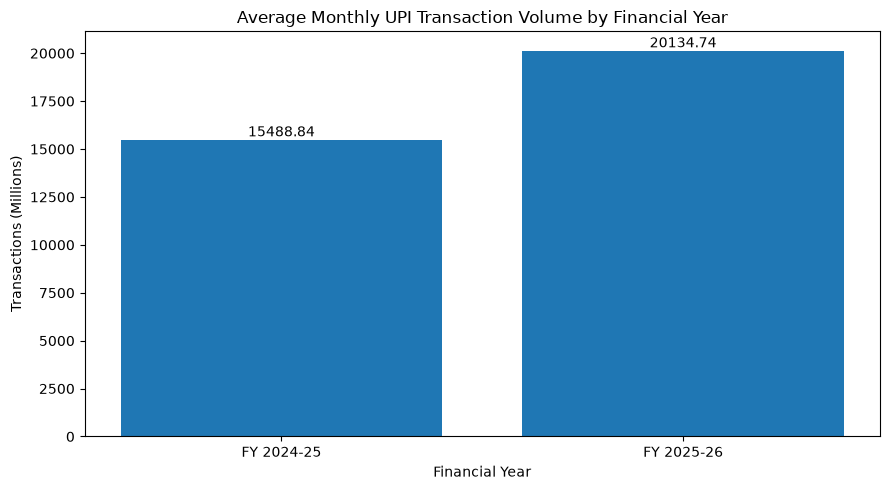

In [45]:
import matplotlib.pyplot as plt

financial_years = ["FY 2024-25", "FY 2025-26"]

average_volumes = [
    fy_2024_25,
    fy_2025_26
]

plt.figure(figsize=(9, 5))

bars = plt.bar(financial_years, average_volumes)

plt.title("Average Monthly UPI Transaction Volume by Financial Year")
plt.xlabel("Financial Year")
plt.ylabel("Transactions (Millions)")

plt.bar_label(bars, fmt="%.2f")

plt.tight_layout()
plt.show()

In [46]:
charts_folder = project_folder / "reports" / "charts"
charts_folder.mkdir(parents=True, exist_ok=True)

plt.savefig(
    charts_folder / "financial_year_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

print("Financial year comparison chart saved!")

Financial year comparison chart saved!


<Figure size 640x480 with 0 Axes>

In [47]:
fy_2024_value = df_2024_clean["Value (In Cr.)"].mean()

fy_2025_value = df_clean["Value (In Cr.)"].mean()

value_growth = (
    (fy_2025_value - fy_2024_value)
    / fy_2024_value
) * 100

print("========== TRANSACTION VALUE COMPARISON ==========")

print(f"FY 2024-25 Average: ₹{fy_2024_value:,.2f} crore")
print(f"FY 2025-26 Average: ₹{fy_2025_value:,.2f} crore")
print(f"Average value growth: {value_growth:.2f}%")

========== TRANSACTION VALUE COMPARISON ==========
FY 2024-25 Average: ₹2,171,412.89 crore
FY 2025-26 Average: ₹2,618,604.14 crore
Average value growth: 20.59%


In [48]:
print("===== UPI GROWTH COMPARISON =====")

print(f"Volume Growth: {fy_growth:.2f}%")
print(f"Value Growth: {value_growth:.2f}%")

if fy_growth > value_growth:
    print("Transaction volume is growing faster than value.")
elif value_growth > fy_growth:
    print("Transaction value is growing faster than volume.")
else:
    print("Both are growing at the same rate.")

===== UPI GROWTH COMPARISON =====
Volume Growth: 30.00%
Value Growth: 20.59%
Transaction volume is growing faster than value.


In [49]:
print("===== AVERAGE TRANSACTION VALUE =====")

print(
    f"FY 2024-25: ₹{df_2024_clean['Value (In Cr.)'].sum() / df_2024_clean['Volume (In Mn.)'].sum() * 10:.2f}"
)

print(
    f"FY 2025-26: ₹{df_clean['Value (In Cr.)'].sum() / df_clean['Volume (In Mn.)'].sum() * 10:.2f}"
)

===== AVERAGE TRANSACTION VALUE =====
FY 2024-25: ₹1401.92
FY 2025-26: ₹1300.54


In [50]:
avg_2024 = (
    df_2024_clean["Value (In Cr.)"].sum()
    / df_2024_clean["Volume (In Mn.)"].sum() * 10
)

avg_2025 = (
    df_clean["Value (In Cr.)"].sum()
    / df_clean["Volume (In Mn.)"].sum() * 10
)

change = ((avg_2025 - avg_2024) / avg_2024) * 100

print("AVERAGE TRANSACTION VALUE CHANGE")
print(f"FY 2024-25: ₹{avg_2024:.2f}")
print(f"FY 2025-26: ₹{avg_2025:.2f}")
print(f"Percentage change: {change:.2f}%")

AVERAGE TRANSACTION VALUE CHANGE
FY 2024-25: ₹1401.92
FY 2025-26: ₹1300.54
Percentage change: -7.23%


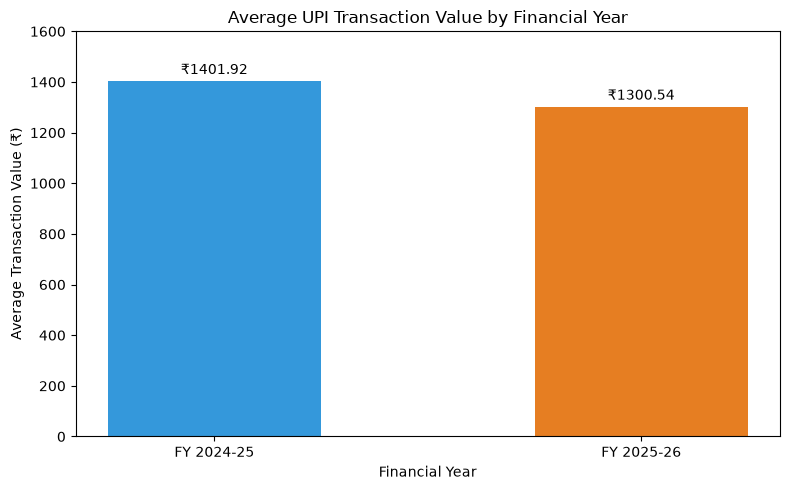

Chart saved successfully!


In [51]:
import matplotlib.pyplot as plt

years = ["FY 2024-25", "FY 2025-26"]
values = [avg_2024, avg_2025]

plt.figure(figsize=(8, 5))

bars = plt.bar(
    years,
    values,
    color=["#3498db", "#e67e22"],
    width=0.5
)

plt.title("Average UPI Transaction Value by Financial Year")
plt.ylabel("Average Transaction Value (₹)")
plt.xlabel("Financial Year")

plt.bar_label(bars, fmt="₹%.2f", padding=3)

plt.ylim(0, 1600)
plt.tight_layout()

# Save the chart before displaying it
plt.savefig(
    charts_folder / "average_transaction_value_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Chart saved successfully!")

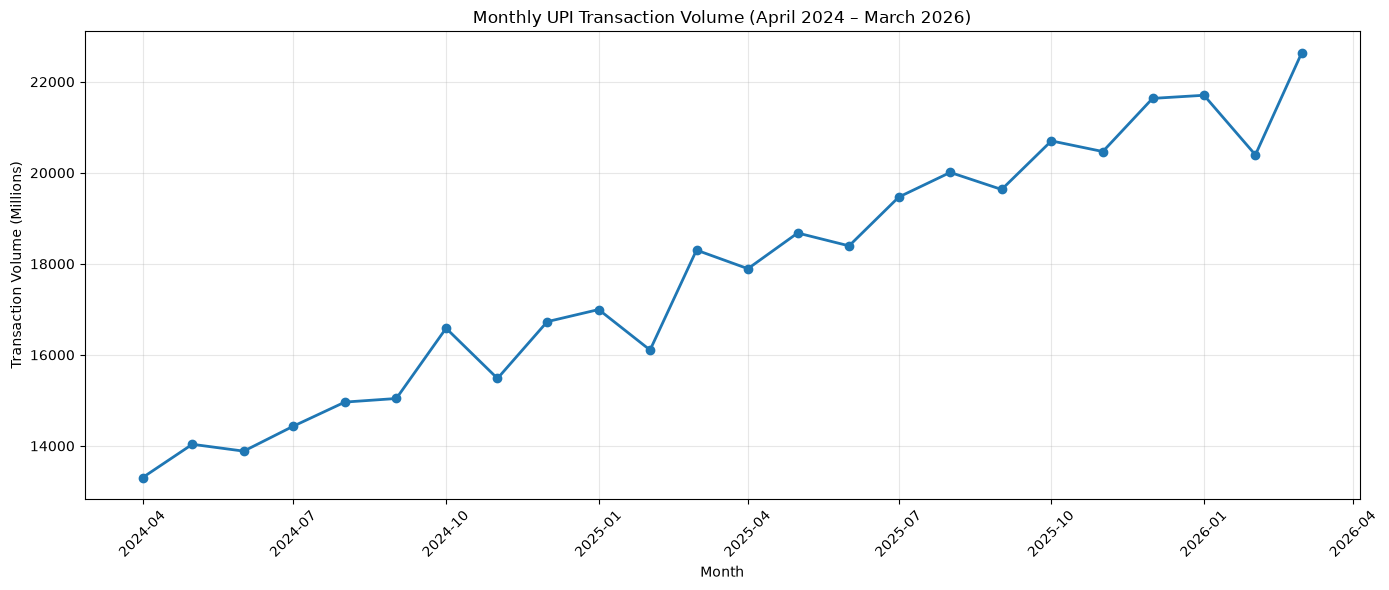

In [52]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_analysis["Month"],
    df_analysis["Volume (In Mn.)"],
    marker="o",
    linewidth=2
)

plt.title("Monthly UPI Transaction Volume (April 2024 – March 2026)")
plt.xlabel("Month")
plt.ylabel("Transaction Volume (Millions)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [53]:
charts_folder = project_folder / "reports" / "charts"

plt.savefig(
    charts_folder / "monthly_upi_volume_24_months.png",
    dpi=300,
    bbox_inches="tight"
)

print("Monthly UPI trend chart saved!")

Monthly UPI trend chart saved!


<Figure size 640x480 with 0 Axes>

In [54]:
highest_growth = df_analysis.loc[
    df_analysis["Volume Growth (%)"].idxmax()
]

lowest_growth = df_analysis.loc[
    df_analysis["Volume Growth (%)"].idxmin()
]

print("===== MONTHLY GROWTH ANALYSIS =====")

print("\nHighest monthly growth:")
print(highest_growth["Month"].strftime("%B %Y"))
print(f"{highest_growth['Volume Growth (%)']:.2f}%")

print("\nLowest monthly growth:")
print(lowest_growth["Month"].strftime("%B %Y"))
print(f"{lowest_growth['Volume Growth (%)']:.2f}%")

===== MONTHLY GROWTH ANALYSIS =====

Highest monthly growth:
March 2025
13.63%

Lowest monthly growth:
November 2024
-6.65%


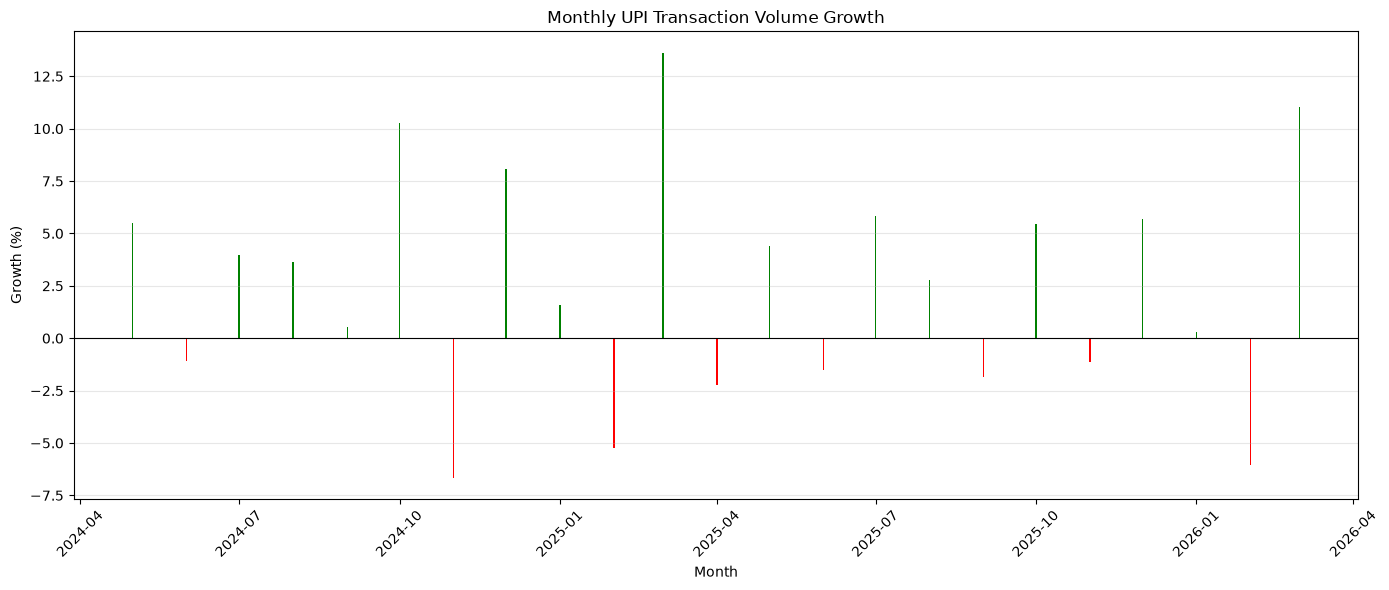

In [55]:
plt.figure(figsize=(14, 6))

colors = [
    "green" if value >= 0 else "red"
    for value in df_analysis["Volume Growth (%)"].fillna(0)
]

plt.bar(
    df_analysis["Month"],
    df_analysis["Volume Growth (%)"],
    color=colors
)

plt.axhline(0, color="black", linewidth=0.8)

plt.title("Monthly UPI Transaction Volume Growth")
plt.xlabel("Month")
plt.ylabel("Growth (%)")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [56]:
charts_folder = project_folder / "reports" / "charts"

plt.savefig(
    charts_folder / "monthly_volume_growth_24_months.png",
    dpi=300,
    bbox_inches="tight"
)

print("Monthly growth chart saved successfully!")

Monthly growth chart saved successfully!


<Figure size 640x480 with 0 Axes>

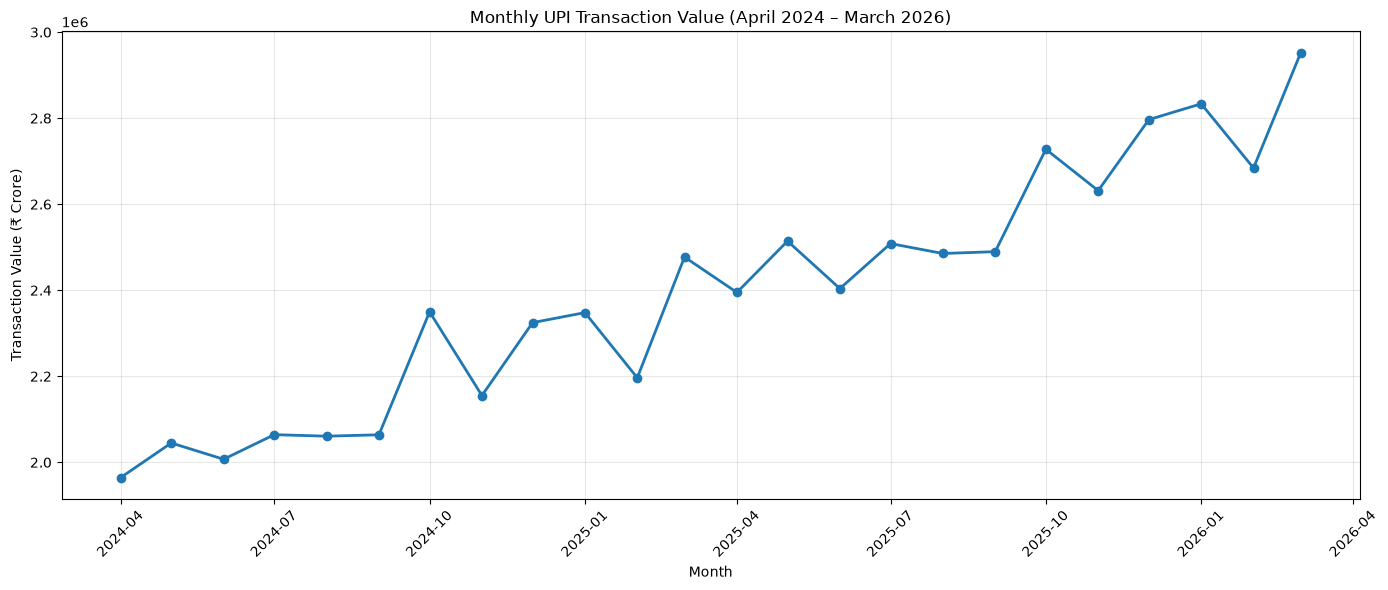

In [57]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_analysis["Month"],
    df_analysis["Value (In Cr.)"],
    marker="o",
    linewidth=2
)

plt.title("Monthly UPI Transaction Value (April 2024 – March 2026)")
plt.xlabel("Month")
plt.ylabel("Transaction Value (₹ Crore)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

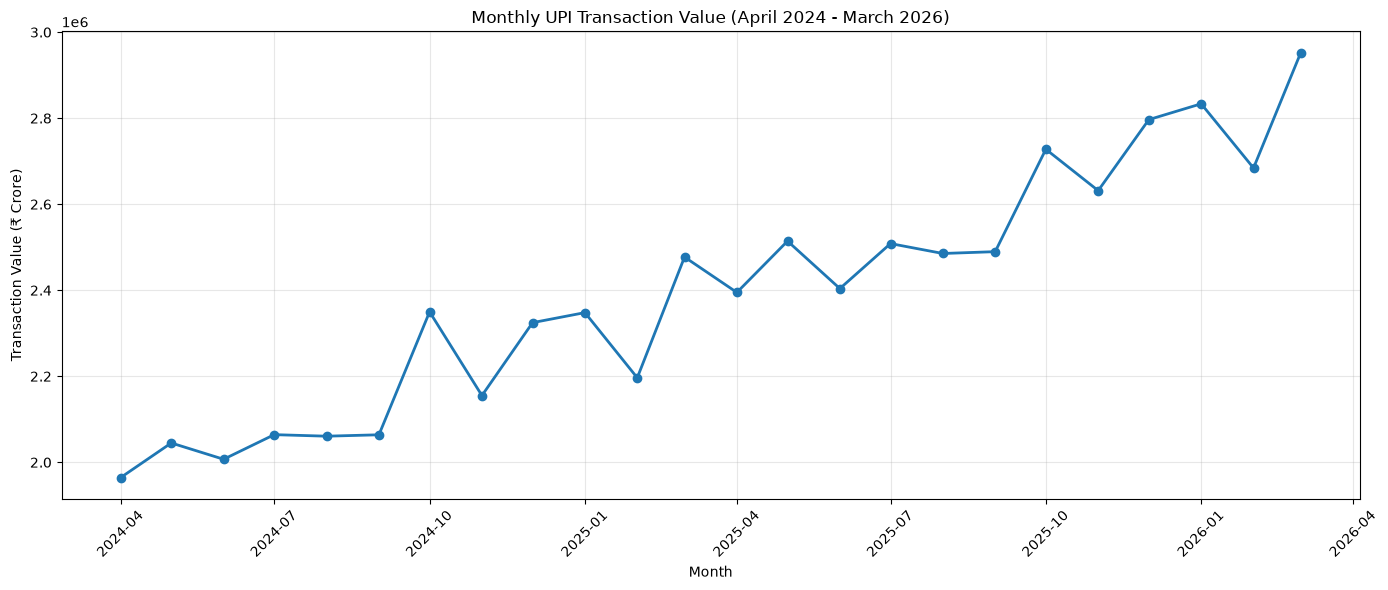

Transaction value chart saved successfully!


In [58]:
plt.figure(figsize=(14, 6))

plt.plot(
    df_analysis["Month"],
    df_analysis["Value (In Cr.)"],
    marker="o",
    linewidth=2
)

plt.title("Monthly UPI Transaction Value (April 2024 - March 2026)")
plt.xlabel("Month")
plt.ylabel("Transaction Value (₹ Crore)")

plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)

plt.tight_layout()

plt.savefig(
    charts_folder / "monthly_upi_value_24_months.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

print("Transaction value chart saved successfully!")

In [59]:
highest_value_growth = df_analysis.loc[
    df_analysis["Value Growth (%)"].idxmax()
]

lowest_value_growth = df_analysis.loc[
    df_analysis["Value Growth (%)"].idxmin()
]

print("===== MONTHLY TRANSACTION VALUE GROWTH =====")

print("\nHighest value growth:")
print(highest_value_growth["Month"].strftime("%B %Y"))
print(f"{highest_value_growth['Value Growth (%)']:.2f}%")

print("\nLowest value growth:")
print(lowest_value_growth["Month"].strftime("%B %Y"))
print(f"{lowest_value_growth['Value Growth (%)']:.2f}%")

===== MONTHLY TRANSACTION VALUE GROWTH =====

Highest value growth:
October 2024
13.85%

Lowest value growth:
November 2024
-8.28%


In [60]:
correlation = df_analysis[
    ["Volume Growth (%)", "Value Growth (%)"]
].corr()

print("===== VOLUME VS VALUE GROWTH CORRELATION =====")
print(correlation)

print(
    "\nCorrelation coefficient:",
    round(correlation.iloc[0, 1], 3)
)

===== VOLUME VS VALUE GROWTH CORRELATION =====
                   Volume Growth (%)  Value Growth (%)
Volume Growth (%)           1.000000          0.947602
Value Growth (%)            0.947602          1.000000

Correlation coefficient: 0.948


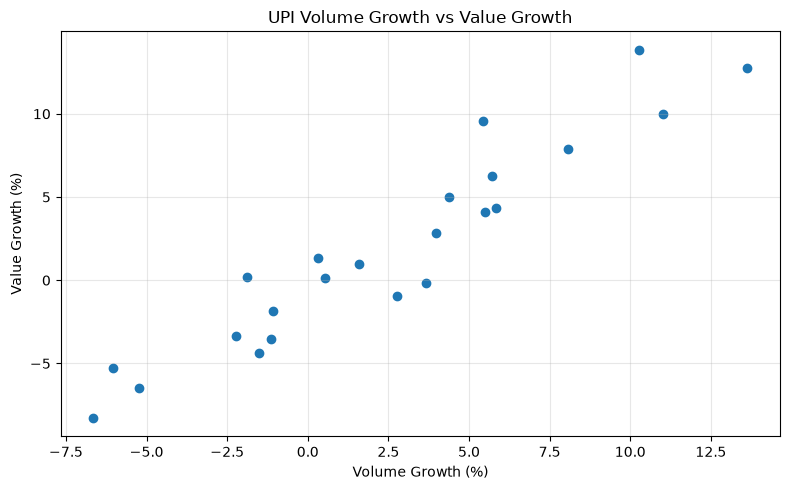

In [61]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_analysis["Volume Growth (%)"],
    df_analysis["Value Growth (%)"]
)

plt.title("UPI Volume Growth vs Value Growth")
plt.xlabel("Volume Growth (%)")
plt.ylabel("Value Growth (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [62]:
output_path = (
    project_folder
    / "data"
    / "processed"
    / "upi_analysis_2024_2026.csv"
)

df_analysis.to_csv(output_path, index=False)

print("Combined analysis dataset saved!")
print("Rows:", len(df_analysis))
print("Columns:", len(df_analysis.columns))
print("Location:", output_path)

Combined analysis dataset saved!
Rows: 24
Columns: 7
Location: c:\Users\krish\Desktop\upi-pulse\data\processed\upi_analysis_2024_2026.csv


In [63]:
saved_df = pd.read_csv(
    output_path,
    parse_dates=["Month"]
)

print("Dataset loaded successfully!")
print("Shape:", saved_df.shape)

print("\nMissing values:")
print(saved_df.isnull().sum())

print("\nFirst 5 rows:")
display(saved_df.head())

Dataset loaded successfully!
Shape: (24, 7)

Missing values:
Month                            0
No. of Banks live on UPI         0
Volume (In Mn.)                  0
Value (In Cr.)                   0
Volume Growth (%)                1
Value Growth (%)                 1
Average Transaction Value (₹)    0
dtype: int64

First 5 rows:


,Month,No. of Banks live on UPI,Volume (In Mn.),Value (In Cr.),Volume Growth (%),Value Growth (%),Average Transaction Value (₹)
0,2024-04-01,583,13303.99,1964464.52,NaN,NaN,1476.598013
1,2024-05-01,598,14035.84,2044937.05,5.500981,4.096410,1456.939556
2,2024-06-01,602,13885.14,2007081.20,-1.073680,-1.851199,1445.488630
3,2024-07-01,605,14435.55,2064292.41,3.964022,2.850468,1430.006068
4,2024-08-01,608,14963.05,2060735.57,3.654173,-0.172303,1377.216256
